In [17]:
import duckdb

In [18]:
from pathlib import Path
import pandas as pd
from IPython.display import display

kalshi_path = Path(
    "/Users/edieespejo/GitHub/data-by-edie/004-love-island/"
    "data/kalshi/kalshi-episodes.csv"
)

name_map = {
    "Alannah": "Alannah Keyser",
    "Amora": "Amora Cacheé Robinson",
    "Aniya": "Aniya Harvey",
    "Beatriz": "Beatriz Hatz",
    "Bryce": "Bryce Alakai Dettloff",
    "Caleb": "Caleb McDaniel",
    "Carl": "Carl Lee Schmidt",
    "Chay": "Chaten Nehra",
    "Corbin": "Corbin Mims",
    "Corey": "Corey Sawyer Jr.",
    "Dylan": "Dylan Wrona",
    "Gabriel": "Gabriel Vasconcelos",
    "Gal": "Gal Tshnieder",
    "Jaiden": "Jaiden Bacciocco",
    "Jen": "Jennifer Terry",
    "Kayda": "Kayda Bosse",
    "KC": "Kuman Chandler",
    "Kenzie": "Mackenzie Annis",
    "Melanie": "Melanie Moreno",
    "Parmida": "Parmida Keshani",
    "Ronnie": "Ronnie Gunter",
    "Sean": "Sean Reifel",
    "Sincere": "Sincere Rhea",
    "Sol": "Sol Dean",
    "Sydney": "Sherleaz Eugene",
    "Tierra": "Tierra Davis",
    "Trinity": "Trinity Tatum",
    "Zach": "Zacharias Georgiou",
    # Note: "Vasana" is in the Kalshi dataset but missing from this map!
}

kalshi_daily = (
    pd.read_csv(kalshi_path)
    .melt(
        id_vars=["timestamp", "episode"], # <-- Added "episode" here
        var_name="kalshi_name",
        value_name="kalshi_price",
    )
)

kalshi_daily["timestamp"] = pd.to_datetime(
    kalshi_daily["timestamp"], utc=True
)
kalshi_daily["kalshi_price"] = pd.to_numeric(
    kalshi_daily["kalshi_price"], errors="raise"
)
kalshi_daily["islander"] = kalshi_daily["kalshi_name"].map(name_map)

# Inspect names that have no match in your Reddit assessments.
# (This will catch "Vasana" based on your current name_map)
display(
    kalshi_daily.loc[
        kalshi_daily["islander"].isna(), ["kalshi_name"]
    ].drop_duplicates()
)

kalshi_daily = (
    kalshi_daily
    .sort_values(["kalshi_name", "timestamp"])
    .reset_index(drop=True)
)

display(kalshi_daily.head())

,kalshi_name
90,Vasana


,timestamp,episode,kalshi_name,kalshi_price,islander
0,2026-05-30 00:00:00+00:00,Pre-Season,Alannah,NaN,Alannah Keyser
1,2026-05-31 00:00:00+00:00,Pre-Season,Alannah,NaN,Alannah Keyser
2,2026-06-01 00:00:00+00:00,Pre-Season,Alannah,NaN,Alannah Keyser
3,2026-06-02 00:00:00+00:00,Episode 1,Alannah,NaN,Alannah Keyser
4,2026-06-03 00:00:00+00:00,Off (Post-Ep 1),Alannah,NaN,Alannah Keyser


In [19]:
kalshi_daily

,timestamp,episode,kalshi_name,kalshi_price,islander
0,2026-05-30 00:00:00+00:00,Pre-Season,Alannah,NaN,Alannah Keyser
1,2026-05-31 00:00:00+00:00,Pre-Season,Alannah,NaN,Alannah Keyser
2,2026-06-01 00:00:00+00:00,Pre-Season,Alannah,NaN,Alannah Keyser
3,2026-06-02 00:00:00+00:00,Episode 1,Alannah,NaN,Alannah Keyser
4,2026-06-03 00:00:00+00:00,Off (Post-Ep 1),Alannah,NaN,Alannah Keyser
...,...,...,...,...,...
1300,2026-07-09 00:00:00+00:00,Episode 32,Zach,3.17,Zacharias Georgiou
1301,2026-07-10 00:00:00+00:00,Episode 33,Zach,2.95,Zacharias Georgiou
1302,2026-07-11 00:00:00+00:00,Episode 34,Zach,2.16,Zacharias Georgiou
1303,2026-07-12 00:00:00+00:00,Episode 35,Zach,2.25,Zacharias Georgiou


In [20]:
# 1. Remove Pre-Season data
kalshi_clean = kalshi_daily[kalshi_daily["episode"] != "Pre-Season"].copy()

# 2. Extract numeric episode (this groups "Episode 1" and "Off (Post-Ep 1)" as simply 1)
kalshi_clean["episode_num"] = kalshi_clean["episode"].str.extract(r"(\d+)")[0].astype("Int64")

# 3. Create the clean episode dataset: group by episode and islander, taking the MAX price
kalshi_episode = (
    kalshi_clean.groupby(["episode_num", "islander"], as_index=False)
    .agg(kalshi_price=("kalshi_price", "max"))
    .rename(columns={"episode_num": "episode", "islander": "target_islander"})
)

# 4. Create the overall dataset: grab the most recent chronological price for each islander
kalshi_overall = (
    kalshi_clean.sort_values("timestamp")
    .groupby("islander", as_index=False)
    .tail(1)[["islander", "kalshi_price"]]
    .rename(columns={"islander": "target_islander"})
)

# 5. Save these clean tables to DuckDB
kalshi_tables = {
    "kalshi_overall_prices": kalshi_overall,
    "kalshi_episode_prices": kalshi_episode,
}

with duckdb.connect(str(db_path)) as con:
    con.execute("CREATE SCHEMA IF NOT EXISTS dashboard")
    con.execute("BEGIN TRANSACTION")
    try:
        for name, frame in kalshi_tables.items():
            # Register the pandas dataframe as a temporary view
            con.register("kalshi_export", frame)
            
            # Write to the database schema
            con.execute(f"CREATE OR REPLACE TABLE dashboard.{name} AS SELECT * FROM kalshi_export")
            
            # Read it back and verify it matches the original dataframe
            saved = con.execute(f"SELECT * FROM dashboard.{name}").df()
            pd.testing.assert_frame_equal(saved, frame.reset_index(drop=True), check_dtype=False)
            
            # Clean up the view
            con.unregister("kalshi_export")
            
        con.execute("COMMIT")
        print(f"Successfully added {list(kalshi_tables.keys())} to DuckDB.")
    except Exception as e:
        con.execute("ROLLBACK")
        raise e

Successfully added ['kalshi_overall_prices', 'kalshi_episode_prices'] to DuckDB.


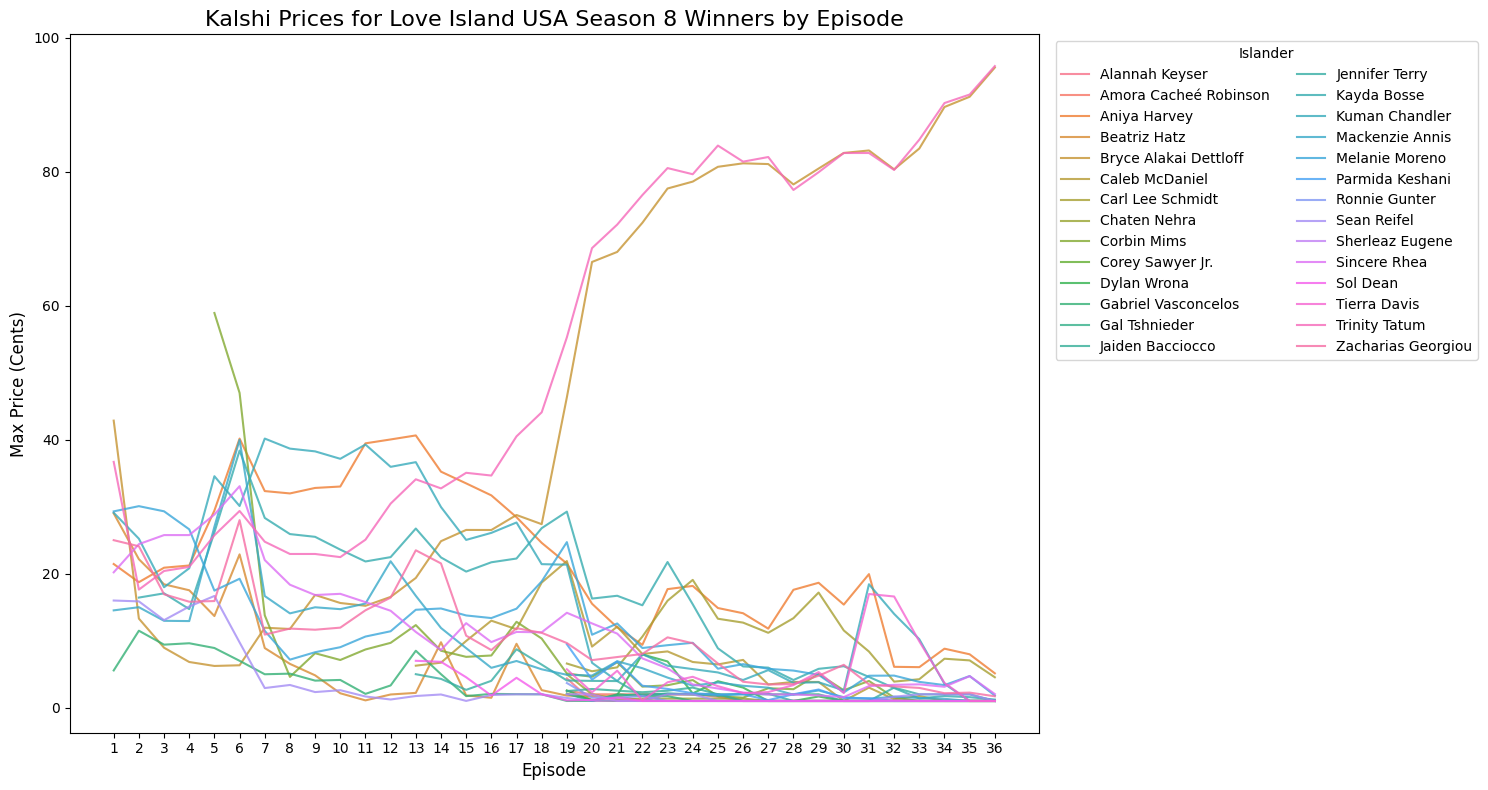

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the figure size to give the plot plenty of horizontal space
plt.figure(figsize=(15, 8))

# Create the line plot using the cleaned episode data
sns.lineplot(
    data=kalshi_episode, 
    x="episode", 
    y="kalshi_price", 
    hue="target_islander",  # Updated to match the renamed column
    alpha=0.8,
    linewidth=1.5
)

# Format the titles and labels
plt.title("Kalshi Prices for Love Island USA Season 8 Winners by Episode", fontsize=16)
plt.xlabel("Episode", fontsize=12)
plt.ylabel("Max Price (Cents)", fontsize=12)

# Ensure the x-axis displays integer ticks for each episode
plt.xticks(range(1, kalshi_episode['episode'].max() + 1))

# Move the legend outside the plot so it doesn't cover the data lines
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left", title="Islander", ncol=2)

# Adjust layout to fit the legend
plt.tight_layout()

# Display the plot
plt.show()

In [23]:
# from pathlib import Path
# import duckdb
# import pandas as pd

# # 1. Define paths (reusing your existing database path)
# project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
# db_path = project_root / "data" / "love_island_reddit.duckdb"
# export_dir = project_root / "tables" / "kalshi_dashboard" 

# # 2. Package the dataframe in a dictionary to reuse the loop structure
# kalshi_tables = {
#     "kalshi_daily_prices": kalshi_daily,
# }

# # 3. Save to DuckDB using transactions and verification
# with duckdb.connect(str(db_path)) as con:
#     con.execute("CREATE SCHEMA IF NOT EXISTS dashboard")
#     con.execute("BEGIN TRANSACTION")
#     try:
#         for name, frame in kalshi_tables.items():
#             # Register the pandas dataframe as a temporary view
#             con.register("kalshi_export", frame)
            
#             # Write to the database schema
#             con.execute(f"CREATE OR REPLACE TABLE dashboard.{name} AS SELECT * FROM kalshi_export")
            
#             # Read it back and verify it matches the original dataframe
#             saved = con.execute(f"SELECT * FROM dashboard.{name}").df()
#             pd.testing.assert_frame_equal(saved, frame.reset_index(drop=True), check_dtype=False)
            
#             # Clean up the view
#             con.unregister("kalshi_export")
            
#         con.execute("COMMIT")
#     except Exception as e:
#         con.execute("ROLLBACK")
#         raise e

# # 4. Export to CSV
# export_dir.mkdir(parents=True, exist_ok=True)
# for name, frame in kalshi_tables.items():
#     csv_path = export_dir / f"{name}.csv"
#     frame.to_csv(csv_path, index=False, encoding="utf-8")
#     print(f"Saved and verified dashboard.{name}: {len(frame):,} rows — DuckDB + CSV")

# print(f"Database: {db_path}")
# print(f"CSV Directory: {export_dir}")